# Downscaling AIFS-ENS over France

AIFS Ensemble 1.0 forecasts 2 m temperature on a 0.25° grid (about 25 km), so a valley and the
mountains around it share one value. This tutorial puts a small downscaler on top of it, trained to
reproduce the 5.5 km CERRA reanalysis over France, and checks what it buys:

- **a. Set up**: install, log in, load the trained downscaler from the Hub.
- **b. Fetch the forecast**: an AIFS-ENS run from Earthmover.
- **c. Apply the downscaler**: turn every member into four 5.5 km maps, and compare the two forecasts.
- **d. Evaluate**: against CERRA, the field the downscaler learned to reproduce, against the floor
  CERRA itself sets, and against independent Météo-France stations.

Everything runs on a CPU in about ten minutes the first time, most of it downscaling the runs
section d needs; an Apple or NVIDIA GPU, picked automatically, is quicker. The runs are saved under
`outputs/tutorial/`, so running the notebook again takes a few minutes.

## a. Set up

Clone the repository and install it; `uv sync` creates the environment, torch included.

```bash
git clone https://github.com/EmmaScharfmann/weather-forecast-model-downscaler
cd weather-forecast-model-downscaler
uv sync
```

The forecasts are read from [Earthmover](https://app.earthmover.io/marketplace/6a10729e8a69e6bcaeae0f90),
which needs a free account and a subscription to the AIFS-ENS dataset. Subscribing creates a
repository under your organisation: put its name in `FORECASTS` below, then authenticate once.

```bash
uv run arraylake auth login        # or: export ARRAYLAKE_TOKEN=ema_...
uv run hf auth login               # the model and datasets below are on the Hugging Face Hub
```

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
from huggingface_hub import hf_hub_download

from downscale.constants import COARSE_CROP_MARGIN_DEG, ZERO_C
from downscale.downscaler import Downscaler
from downscale.evaluation import (
    at_valid_times, combine_leads, elevation_scores, lead_scores, pooled, stack_members, station_rmse,
)
from downscale.fetch import get_target
from downscale.inference import downscale_forecast, save_downscaled
from downscale.plots import (
    TERRAIN_CMAP, elevation_figure, lead_figure, map_grid, maps, native_cells, plume_figure, station_maps,
)
from downscale.regions import parse_region
from downscale.sources import (
    available_inits, fetch_forecast, forecast_box, open_forecasts, save_forecast, store_name,
)
from downscale.station_interp import curvilinear_for
from downscale.stations import load_published_stations

MODEL_REPO = "EmmaScharfmann/france-temperature-downscaler"
FORECASTS = "emmahf/ecmwf-aifs-ens-forecast-subscription"   # your Earthmover subscription
FORECASTS_2020 = "hf://datasets/EmmaScharfmann/aifs-ens-france-aug2020"
CERRA_REPO = "EmmaScharfmann/cerra-france-t2m-2016-2020"
STATIONS = "EmmaScharfmann/france-stations"   # Météo-France, Aug 2020, Aug 2025, Jan, Jun-Jul 2026

MEMBERS = 10          # AIFS-ENS members to downscale, out of 51
MAX_LEAD_HOURS = 240
SAMPLES = 4           # downscaled maps per member in section c: 10 members become 40
EVAL_SAMPLES = 1      # in section d: both ensembles keep 10 members, and downscaling is 4x faster
BOX = forecast_box(parse_region("france"), COARSE_CROP_MARGIN_DEG)
OUT = Path("outputs/tutorial")   # every forecast is fetched and downscaled once, then read from here

/tmp/claude-1000/-Users-emma-Code-HuggingFace-downscaling/90b4154b-0fe0-4dfa-b2f6-12b5484cfb24/scratchpad/nbenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


The checkpoint holds the network, the normalisation statistics and everything static the model needs:
the 5.5 km grid, its elevation and land-sea mask, the coarse model's elevation and the distance to the
coast. Nothing else has to be downloaded to run it.

In [2]:
model = Downscaler.load(hf_hub_download(MODEL_REPO, "model.pt"))
LAND = xr.DataArray(model.static["land_sea_mask"] > 0.5, dims=("y", "x"))
print(f"fine grid {model.lat.shape[0]} x {model.lat.shape[1]} on {model.device}, {model.net.cfg}")

fine grid 228 x 238 on cpu, Config(loss='crps', base=32, depth=3, noise_channels=2, upsample='bilinear', noise_fine_fraction=0.0, noise_coarse_factor=[8, 16], coast_distance=True)


## b. Fetch the AIFS-ENS forecast

The Earthmover archive holds every AIFS-ENS run since July 2025: 51 members, 6-hourly lead times out to
15 days, on the global 0.25° grid. Opening it reads only the metadata; `fetch_forecast` then reads one
initialisation over France, with a margin so that interpolating onto the fine grid never runs off the
edge. Temperatures come back in kelvin.

We take the run of 11 August 2025, at the start of that month's heatwave.

In [3]:
archive = open_forecasts(FORECASTS)
inits = available_inits(archive)
print(f"{len(inits)} complete initialisations, {inits[0]:%Y-%m-%d %H}Z to {inits[-1]:%Y-%m-%d %H}Z")

INIT = pd.Timestamp("2025-08-11 00:00")
coarse = fetch_forecast(archive, INIT, BOX, members=MEMBERS, max_lead_hours=MAX_LEAD_HOURS)
coarse

1900 complete initialisations, 2025-07-02 00Z to 2026-10-19 18Z


<xarray.DataArray 't2m' (time: 1, lead_time: 41, ensemble: 10, lat: 65, lon: 85)> Size: 9MB
array([[[[[288.4   , 288.0875, 287.775 , ..., 289.9   , 289.775 ,
           289.4   ],
          [288.275 , 288.0875, 287.9625, ..., 288.9   , 288.7125,
           288.15  ],
          [288.3375, 288.2125, 288.275 , ..., 287.15  , 286.4   ,
           286.025 ],
          ...,
          [294.4   , 295.65  , 297.025 , ..., 299.525 , 299.525 ,
           299.4   ],
          [295.025 , 295.775 , 297.025 , ..., 299.525 , 299.525 ,
           299.4   ],
          [294.775 , 295.525 , 296.775 , ..., 299.15  , 299.275 ,
           299.525 ]],

         [[288.2125, 287.775 , 287.0875, ..., 289.525 , 289.4   ,
           289.275 ],
          [288.025 , 287.7125, 287.4   , ..., 288.5875, 288.3375,
           287.8375],
          [288.2125, 287.9   , 287.9625, ..., 286.9   , 286.15  ,
           285.5875],
...
          [291.15  , 291.275 , 291.65  , ..., 299.4   , 299.4   ,
           299.65  ],
          [291.4   , 291.4   , 291.775 , ..., 299.275 , 299.275 ,
           299.525 ],
          [291.65  , 291.775 , 292.525 , ..., 299.15  , 299.275 ,
           299.4   ]],

         [[289.15  , 288.4   , 287.4625, ..., 292.15  , 291.525 ,
           290.4   ],
          [288.525 , 288.4625, 287.8375, ..., 289.525 , 289.275 ,
           288.5875],
          [288.15  , 288.2125, 288.525 , ..., 288.025 , 286.775 ,
           286.5875],
          ...,
          [290.275 , 290.525 , 290.9   , ..., 299.525 , 299.525 ,
           299.525 ],
          [290.4   , 290.025 , 290.4   , ..., 299.4   , 299.4   ,
           299.4   ],
          [291.025 , 290.65  , 291.275 , ..., 299.15  , 299.025 ,
           299.025 ]]]]], shape=(1, 41, 10, 65, 85), dtype=float32)
Coordinates:
  * time       (time) datetime64[ns] 8B 2025-08-11
  * lead_time  (lead_time) timedelta64[ns] 328B 0 days 00:00:00 ... 10 days 0...
  * ensemble   (ensemble) int16 20B 0 1 2 3 4 5 6 7 8 9
  * lat        (lat) float64 520B 54.5 54.25 54.0 53.75 ... 39.0 38.75 38.5
  * lon        (lon) float64 680B -8.5 -8.25 -8.0 -7.75 ... 12.0 12.25 12.5
Attributes:
    units:    K

## c. Apply the downscaler

`downscale_forecast` interpolates each member onto the 5.5 km grid, which is also the baseline the
model must beat, and passes it through the network `SAMPLES` times. The network predicts the
correction to add to the interpolated field, from the field itself, the static maps, the time of day
and of year, and a draw of noise. The noise is what makes the samples differ.

In [4]:
downscaled = downscale_forecast(model, coarse, samples=SAMPLES)
fine = stack_members(downscaled)   # (time, lead_time, member, y, x), 40 members
print(dict(downscaled.t2m_ds.sizes))

# Keep both, so section d evaluates this run without fetching or downscaling it again.
save_forecast(coarse, OUT / "forecasts")
save_downscaled(downscaled, OUT / "downscaled" / store_name(INIT))

{'time': 1, 'lead_time': 41, 'ensemble': 10, 'sample': 4, 'y': 228, 'x': 238}


/tmp/claude-1000/-Users-emma-Code-HuggingFace-downscaling/90b4154b-0fe0-4dfa-b2f6-12b5484cfb24/scratchpad/nbenv/lib/python3.13/site-packages/zarr/api/asynchronous.py:260: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


/tmp/claude-1000/-Users-emma-Code-HuggingFace-downscaling/90b4154b-0fe0-4dfa-b2f6-12b5484cfb24/scratchpad/nbenv/lib/python3.13/site-packages/zarr/api/asynchronous.py:260: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


PosixPath('outputs/tutorial/downscaled/aifs-ens_20250811T0000.zarr')

### The two forecasts side by side

The top row shows the ensemble mean on the afternoon of 13 August: AIFS-ENS on its own 0.25° cells,
and the downscaled forecast at 5.5 km. Both are masked over the sea, because the model was trained on
land only: CERRA's sea surface temperature comes from a different process.

The bottom row explains the difference. The correction the downscaler adds follows the terrain:
colder on the ridges of the Alps, the Pyrenees and the Massif Central, warmer in the valleys and the
Rhône corridor, which the coarse grid averages with the mountains around them.

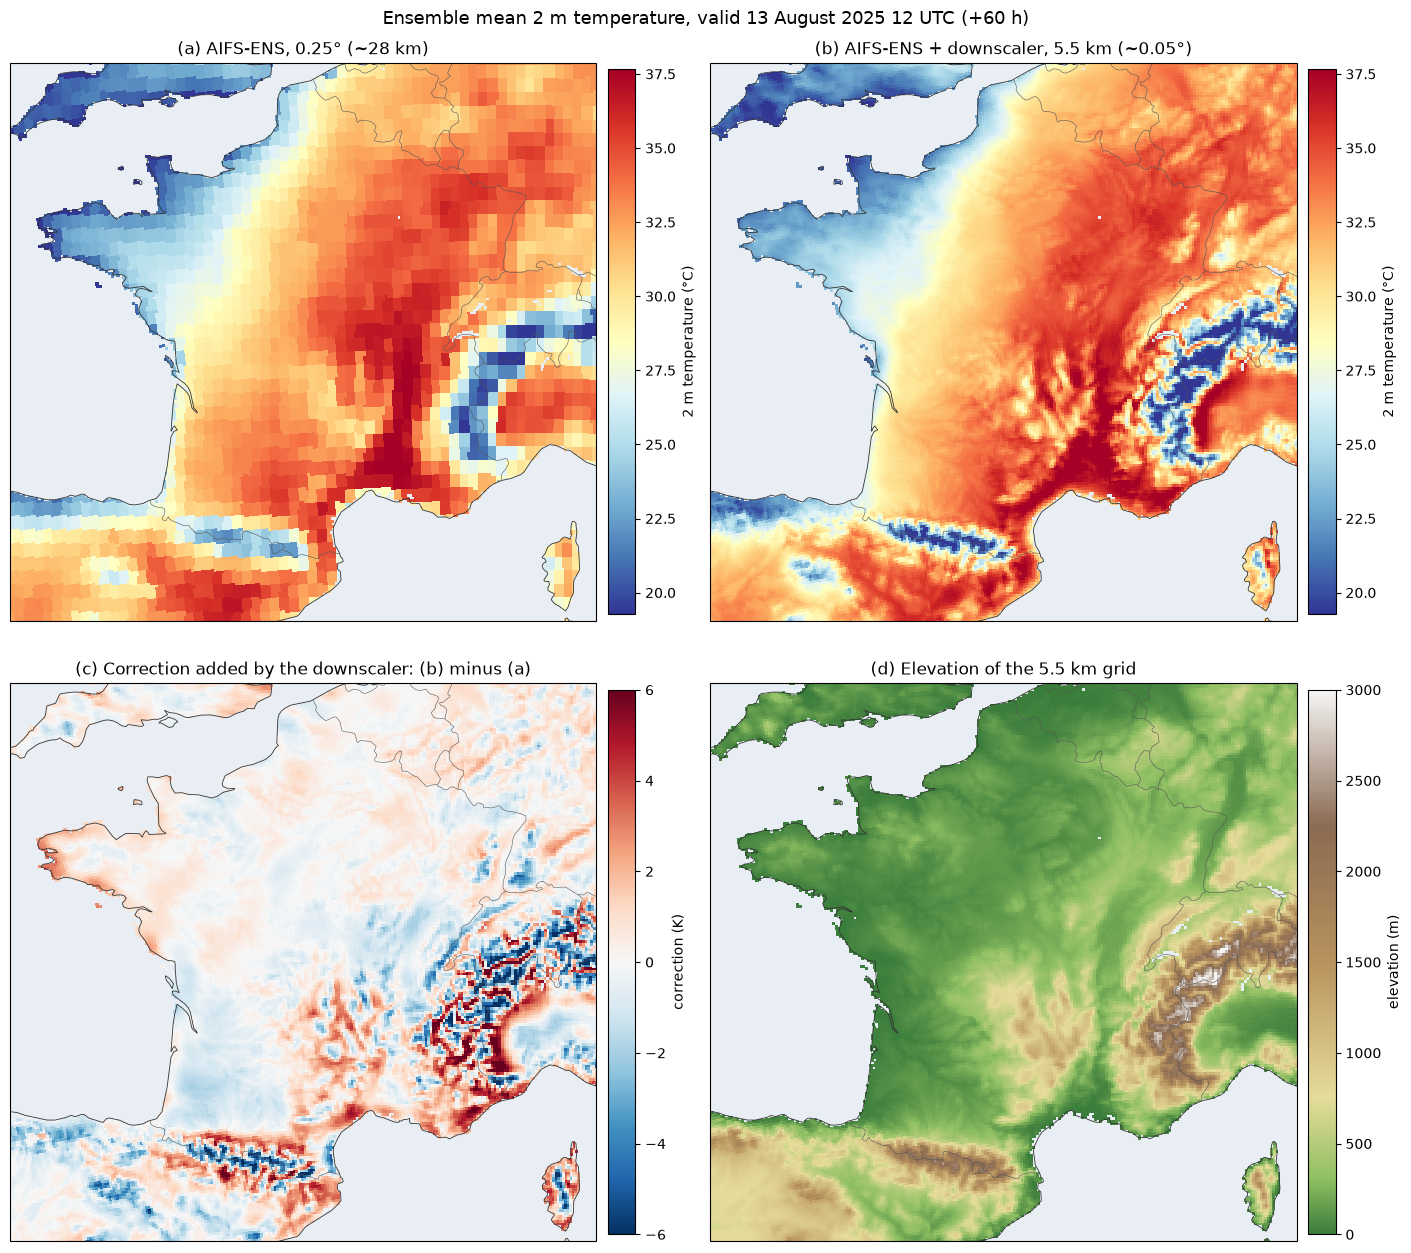

In [5]:
LEAD = 60   # hours: 12 UTC on 13 August
k = int(np.flatnonzero(coarse.lead_time.values == np.timedelta64(LEAD, "h"))[0])
valid = pd.Timestamp(downscaled.valid_time.values[0, k])

# AIFS-ENS on its own 0.25° cells, drawn on the fine grid so the same land-sea mask hides the sea.
raw_mean = native_cells(coarse.isel(time=0, lead_time=k).mean("ensemble") - ZERO_C, model.lat, model.lon, LAND.values)
fine_mean = fine.isel(time=0, lead_time=k).mean("member").where(LAND).values - ZERO_C
interp_mean = downscaled.t2m_interp.isel(time=0, lead_time=k).mean("ensemble").where(LAND).values - ZERO_C
elevation = np.where(LAND, model.static["cerra_orography"], np.nan)

LABELS = {
    "title": f"Ensemble mean 2 m temperature, valid {valid:%d %B %Y %H} UTC (+{LEAD} h)",
    "coarse": "(a) AIFS-ENS, 0.25° (~28 km)",
    "downscaled": "(b) AIFS-ENS + downscaler, 5.5 km (~0.05°)",
    "added": "(c) Correction added by the downscaler: (b) minus (a)",
    "elevation": "(d) Elevation of the 5.5 km grid",
    "temperature_unit": "2 m temperature (°C)",
    "correction_unit": "correction (K)",
    "elevation_unit": "elevation (m)",
}
low, high = np.nanpercentile(np.concatenate([raw_mean.ravel(), fine_mean.ravel()]), [1, 99])
fig = map_grid([
    dict(title=LABELS["coarse"], lon=model.lon, lat=model.lat, values=raw_mean,
         vmin=low, vmax=high, label=LABELS["temperature_unit"]),
    dict(title=LABELS["downscaled"], lon=model.lon, lat=model.lat, values=fine_mean,
         vmin=low, vmax=high, label=LABELS["temperature_unit"]),
    dict(title=LABELS["added"], lon=model.lon, lat=model.lat, values=fine_mean - interp_mean,
         cmap="RdBu_r", vmin=-6, vmax=6, label=LABELS["correction_unit"]),
    dict(title=LABELS["elevation"], lon=model.lon, lat=model.lat, values=elevation,
         cmap=TERRAIN_CMAP, vmin=0, vmax=3000, label=LABELS["elevation_unit"]),
], title=LABELS["title"])

Zooming on the French Alps makes the gain in resolution plain. On the coarse grid, the Rhône valley,
the Isère valley around Grenoble and the high ground from Mont Blanc to the Écrins are a few dozen
cells; at 5.5 km each valley stands out from the ridges around it.

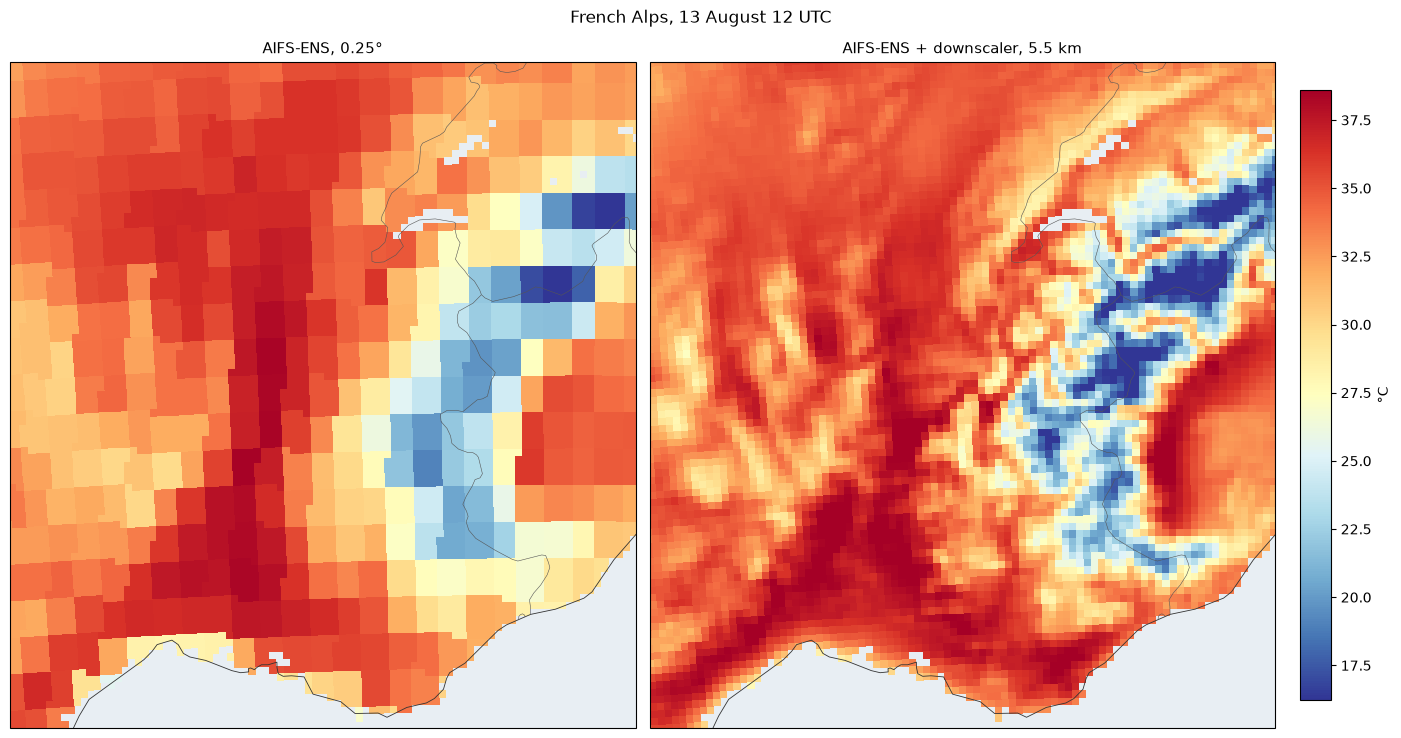

In [6]:
ALPS = (2.5, 8.5, 43.0, 47.5)   # lon_min, lon_max, lat_min, lat_max
inside = (model.lon >= ALPS[0]) & (model.lon <= ALPS[1]) & (model.lat >= ALPS[2]) & (model.lat <= ALPS[3])
low, high = np.nanpercentile(np.concatenate([raw_mean[inside], fine_mean[inside]]), [1, 99])
fig = maps([
    ("AIFS-ENS, 0.25°", model.lon, model.lat, raw_mean),
    ("AIFS-ENS + downscaler, 5.5 km", model.lon, model.lat, fine_mean),
], extent=ALPS, vmin=low, vmax=high, width=6.5, title=f"French Alps, {valid:%d %B %H} UTC")

### One point, every member

Grenoble sits at 213 m at the bottom of a deep valley. Its AIFS-ENS cell also covers the
Chartreuse and Belledonne massifs, so the raw forecast is too cold there every afternoon. The plume
shows each member at the station over the ten days, with the observations.

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

Fetching 7 files: 100%|██████████| 7/7 [00:00<00:00, 1255.08it/s]

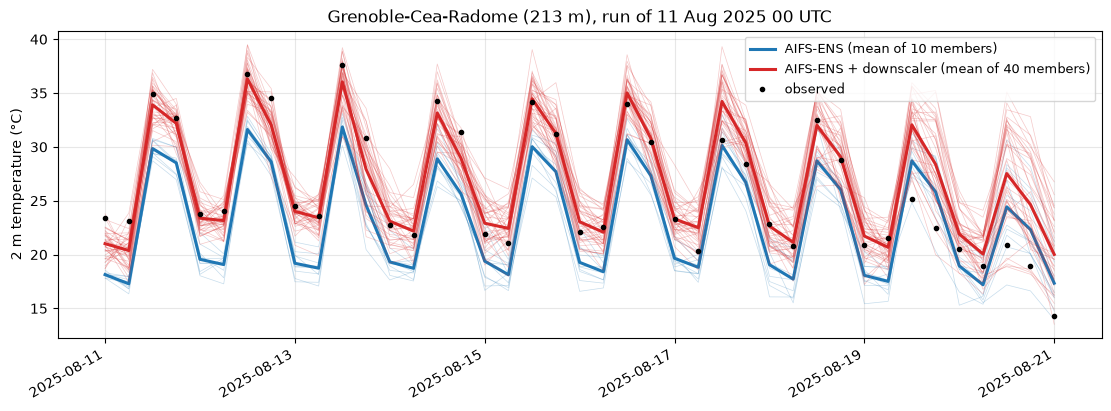

In [7]:
stations_2025 = load_published_stations(STATIONS, start="2025-08-01", end="2025-08-31")
site = stations_2025.sel(station=["38185012"])   # GRENOBLE-CEA-RADOME
times = pd.DatetimeIndex(downscaled.valid_time.values[0])

raw_at_site = coarse.isel(time=0).interp(lat=float(site.latitude[0]), lon=float(site.longitude[0]))
read_site = curvilinear_for(model.lat, model.lon, site).apply
fine_at_site = read_site(fine.isel(time=0)).isel(station=0)
observed = site.t2m.isel(station=0).reindex(time=times).values

fig = plume_figure(times, {
    "AIFS-ENS": raw_at_site.transpose("ensemble", "lead_time").values - ZERO_C,
    "AIFS-ENS + downscaler": fine_at_site.transpose("member", "lead_time").values - ZERO_C,
}, observed - ZERO_C, title=f"{site['name'].item().title()} ({int(site.elevation[0])} m), run of {INIT:%d %b %Y %H} UTC")

## d. Evaluate

A forecast can be scored against two kinds of truth, which answer different questions.

- **CERRA**, the reanalysis the downscaler learned to reproduce. Comparing with it shows how much of
  the 5.5 km detail the model actually learned. CERRA on the Hub covers 2014 to 2020, so this part
  uses AIFS-ENS forecasts for August 2020, run from ERA5 initial conditions with
  [earth2studio-pipeline](https://github.com/EmmaScharfmann/earth2studio-pipeline) and published on the Hub.
- **Weather stations**, which the model never saw. CERRA is itself an estimate with errors of its own,
  so its distance to the stations is a **floor**: a downscaler trained to reproduce CERRA cannot get
  closer to the stations than CERRA does. The gap between the coarse forecast and that floor is what
  downscaling could at best remove.

Every score below is computed over land, for the ensemble mean (RMSE, bias) and for the whole ensemble
(fair CRPS, spread). AIFS-ENS is scored after bilinear interpolation, the baseline the downscaler starts
from.

Evaluation needs more runs than the one above. `run` fetches and downscales an initialisation once
and saves both forecasts under `outputs/tutorial/`; any run already there, such as the one from
section c, is read back instead. `score` then only scores: it never fetches or downscales.

To keep this fast, section d draws `EVAL_SAMPLES = 1` map per member, so AIFS-ENS and AIFS-ENS +
downscaler are both 10-member ensembles and the comparison is like for like.

In [8]:
def run(archive, init):
    """The coarse and downscaled forecasts of one initialisation, computed once and saved."""
    name = store_name(init)
    path = OUT / "downscaled" / name
    if not path.exists():
        coarse = fetch_forecast(archive, init, BOX, members=MEMBERS, max_lead_hours=MAX_LEAD_HOURS)
        save_forecast(coarse, OUT / "forecasts")
        save_downscaled(downscale_forecast(model, coarse, samples=EVAL_SAMPLES), path)
    return xr.open_zarr(OUT / "forecasts" / name)["t2m"], xr.open_zarr(path)


def score(downscaled, stations, cerra=None, short_leads=48):
    """Score one downscaled run against the stations and, when given, against CERRA."""
    downscaled = downscaled.isel(sample=slice(0, EVAL_SAMPLES))   # the run from section c has more
    forecasts = {
        "AIFS-ENS": downscaled.t2m_interp.rename(ensemble="member").load(),
        "AIFS-ENS + downscaler": stack_members(downscaled).load(),
    }
    read = curvilinear_for(model.lat, model.lon, stations).apply
    observed = at_valid_times(stations.t2m, downscaled.valid_time)          # (time, lead_time, station)
    out = {"stations": {}, "means": {}}
    short = downscaled.lead_time <= np.timedelta64(short_leads, "h")
    for name, forecast in forecasts.items():
        at = read(forecast)
        out["stations"][name] = lead_scores(at, observed)
        out["means"][name] = at.mean("member").sel(lead_time=short).values
    out["observed"] = observed.sel(lead_time=short).values
    if cerra is not None:
        truth = at_valid_times(cerra.t2m, downscaled.valid_time)             # (time, lead_time, y, x)
        out["cerra"] = {name: lead_scores(f, truth.where(LAND)) for name, f in forecasts.items()}
        at = read(truth)                                                     # CERRA at the stations
        out["stations"]["CERRA"] = lead_scores(at, observed)                  # same valid times: the floor
        out["means"]["CERRA"] = at.sel(lead_time=short).values
    return out

### d.1 Against CERRA, August 2020

The 2020 forecasts are read like the Earthmover archive. The Hub dataset is one Zarr store with the same
dimensions.

In [9]:
archive_2020 = open_forecasts(FORECASTS_2020)
inits_2020 = available_inits(archive_2020)
cerra, _ = get_target(inits_2020[0], inits_2020[-1] + pd.Timedelta(hours=MAX_LEAD_HOURS), repo=CERRA_REPO,
                      load=True)   # about 30 MB, read once rather than streamed
stations_2020 = load_published_stations(STATIONS, start="2020-08-01", end="2020-08-31")
print(f"{len(inits_2020)} initialisations, {inits_2020[0]:%d %b} to {inits_2020[-1]:%d %b %Y}; "
      f"{stations_2020.sizes['station']} stations")

runs_2020 = {init: run(archive_2020, init) for init in inits_2020}
results_2020 = [score(downscaled_2020, stations_2020, cerra) for _, downscaled_2020 in runs_2020.values()]

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

Fetching 7 files: 100%|██████████| 7/7 [00:00<00:00, 963.83it/s]

14 initialisations, 01 Aug to 27 Aug 2020; 1516 stations


The maps compare the first run with CERRA one day ahead, where the large-scale forecast is still
good and most of the remaining error is local. The top row shows the fields, the bottom row their
errors against CERRA.

AIFS-ENS                 RMSE against CERRA over land 2.04 K
AIFS-ENS + downscaler    RMSE against CERRA over land 1.51 K


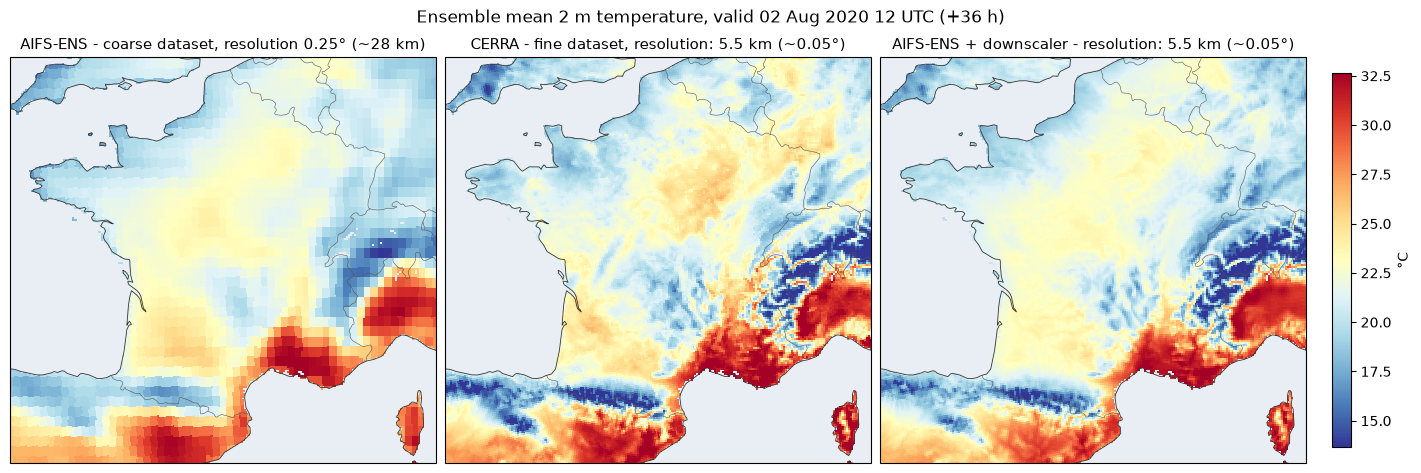

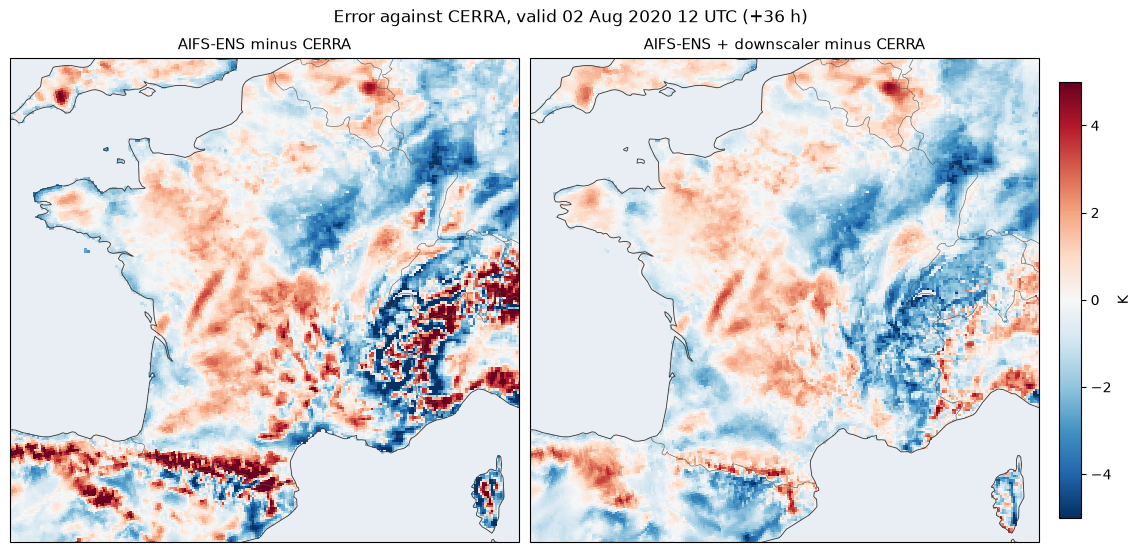

In [10]:
coarse_first, first = runs_2020[inits_2020[0]]
k = int(np.flatnonzero(first.lead_time.values == np.timedelta64(36, "h"))[0])
valid_2020 = pd.Timestamp(first.valid_time.values[0, k])

raw = native_cells(coarse_first.isel(time=0, lead_time=k).mean("ensemble").load() - ZERO_C,
                   model.lat, model.lon, LAND.values)
interp = first.t2m_interp.isel(time=0, lead_time=k).mean("ensemble").where(LAND).values - ZERO_C
down = stack_members(first).isel(time=0, lead_time=k).mean("member").where(LAND).values - ZERO_C
truth = cerra.t2m.sel(time=valid_2020).where(LAND).values - ZERO_C

when = f"valid {valid_2020:%d %b %Y %H} UTC (+36 h)"
fig = maps([
    ("AIFS-ENS - coarse dataset, resolution 0.25° (~28 km)", model.lon, model.lat, raw),
    ("CERRA - fine dataset, resolution: 5.5 km (~0.05°)", model.lon, model.lat, truth),
    ("AIFS-ENS + downscaler - resolution: 5.5 km (~0.05°)", model.lon, model.lat, down),
], width=4.4, title=f"Ensemble mean 2 m temperature, {when}")
fig = maps([
    ("AIFS-ENS minus CERRA", model.lon, model.lat, interp - truth),
    ("AIFS-ENS + downscaler minus CERRA", model.lon, model.lat, down - truth),
], cmap="RdBu_r", vmin=-5, vmax=5, label="K", title=f"Error against CERRA, {when}")
for name, error in [("AIFS-ENS", interp - truth), ("AIFS-ENS + downscaler", down - truth)]:
    print(f"{name:24s} RMSE against CERRA over land {np.sqrt(np.nanmean(error ** 2)):.2f} K")

Over every run and lead time: the downscaler removes a roughly constant amount of error. That is the
local part, which does not grow with lead time; the large-scale error does grow, and the downscaler
leaves it alone, as it should.

,AIFS-ENS,AIFS-ENS + downscaler
rmse_K,2.258,1.928
bias_K,0.158,-0.261
crps_K,1.210,0.958
spread_K,1.542,1.846


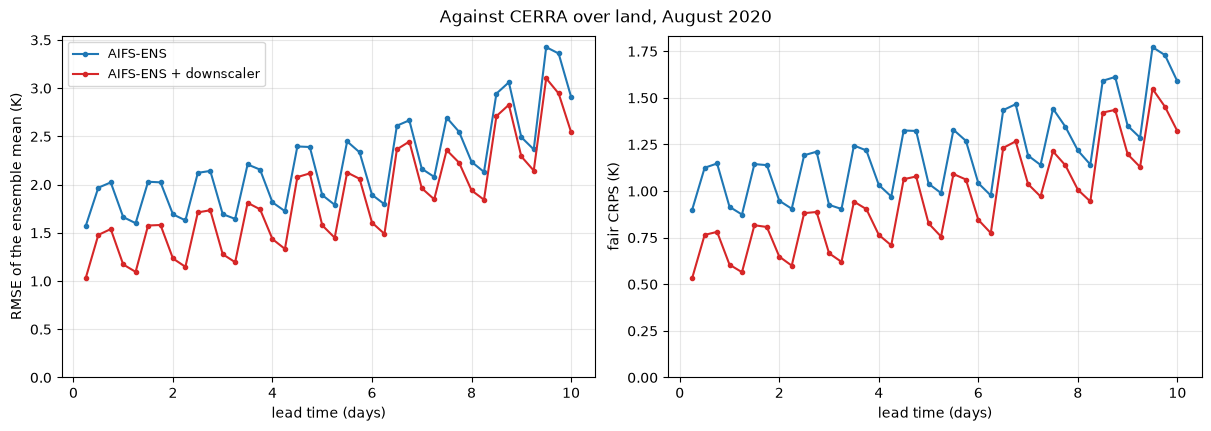

In [11]:
cerra_scores = {name: combine_leads([r["cerra"][name] for r in results_2020])
                for name in ("AIFS-ENS", "AIFS-ENS + downscaler")}
fig = lead_figure(cerra_scores, metrics=("rmse_K", "crps_K"), title="Against CERRA over land, August 2020")
pd.DataFrame({name: pooled(t) for name, t in cerra_scores.items()}).round(3)

### d.2 Against stations, with the floor, August 2020

The same forecasts, now read at the Météo-France stations. The dashed curve is CERRA's own error at the
same stations and valid times: the best a downscaler trained on CERRA can do. CERRA does not depend on
lead time, but each lead verifies at a different time of day (+12 h and +36 h at 12 UTC, +6 h at 06 UTC,
...), so the floor zigzags with the daily cycle like the forecasts do.

first 48 h: AIFS-ENS 2.29 K, + downscaler 1.97 K, CERRA 1.75 K; the downscaler closes 59% of the gap to the floor


,AIFS-ENS,AIFS-ENS + downscaler,CERRA
rmse_K,2.589,2.359,1.725
bias_K,-0.232,-0.560,-0.179
crps_K,1.450,1.247,1.222
spread_K,1.489,1.815,0.000


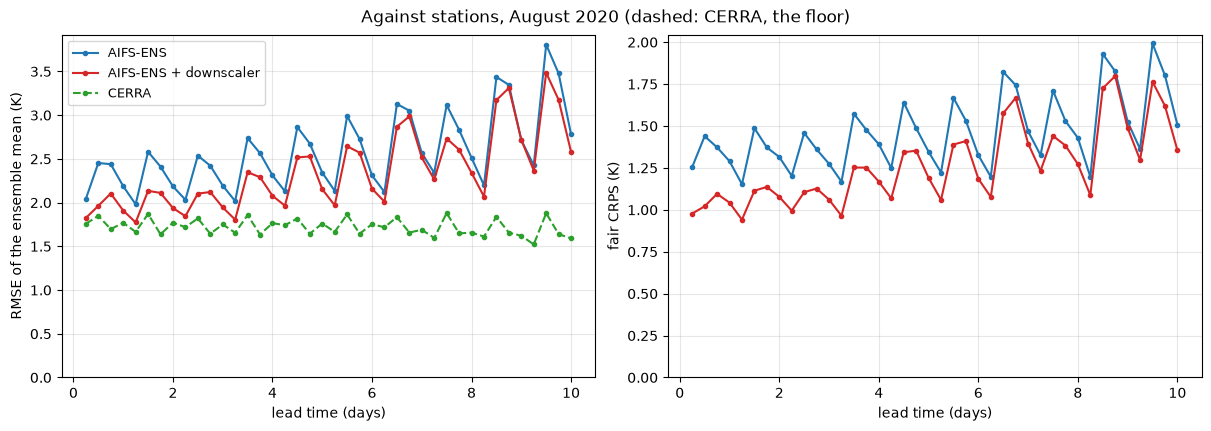

In [12]:
# Pool the 14 runs, lead time by lead time. CERRA is scored at the same stations and valid times as
# the forecasts, so each lead has its own floor: it moves with the time of day the lead verifies at.
NAMES = ("AIFS-ENS", "AIFS-ENS + downscaler", "CERRA")
station_scores_2020 = {name: combine_leads([r["stations"][name] for r in results_2020]) for name in NAMES}
fig = lead_figure(station_scores_2020, metrics=("rmse_K", "crps_K"), references=["CERRA"],
                  title="Against stations, August 2020 (dashed: CERRA, the floor)")

# One number per forecast, over every lead, then over the first 48 h only.
summary = pd.DataFrame({name: pooled(table) for name, table in station_scores_2020.items()})
first_48h = pd.DataFrame({name: pooled(table.query("lead_hours <= 48"))
                          for name, table in station_scores_2020.items()})

# Share of the gap between AIFS-ENS and the floor that the downscaler closes, within 48 h.
raw, down, floor = first_48h.loc["rmse_K", list(NAMES)]
print(f"first 48 h: AIFS-ENS {raw:.2f} K, + downscaler {down:.2f} K, CERRA {floor:.2f} K; "
      f"the downscaler closes {(raw - down) / (raw - floor):.0%} of the gap to the floor")
summary.round(3)

The floor differs with the terrain. Split by station elevation, over the first 48 hours where the
large-scale error is still small, the gain is largest in the mountains, where the 0.25° grid is most
wrong about the height of the ground.

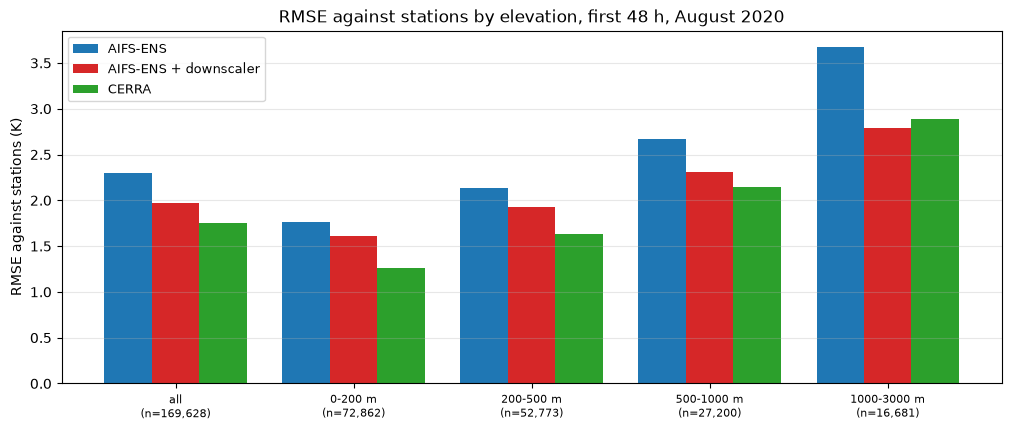

In [13]:
names = ("AIFS-ENS", "AIFS-ENS + downscaler", "CERRA")
fields = {name: np.concatenate([r["means"][name].reshape(-1, r["means"][name].shape[-1]) for r in results_2020])
          for name in names}
observed = np.concatenate([r["observed"].reshape(-1, r["observed"].shape[-1]) for r in results_2020])
bands = elevation_scores(fields, observed, stations_2020.elevation.values, [0, 200, 500, 1000, 3000])
fig = elevation_figure(bands, title="RMSE against stations by elevation, first 48 h, August 2020")

The same scores station by station. The two maps on top share one colour scale: AIFS-ENS is worst in the
Alps, the Pyrenees, the Massif Central and Corsica, where its cells are furthest from the height of the
stations. The map below is the difference, green where the downscaler lowers the RMSE.

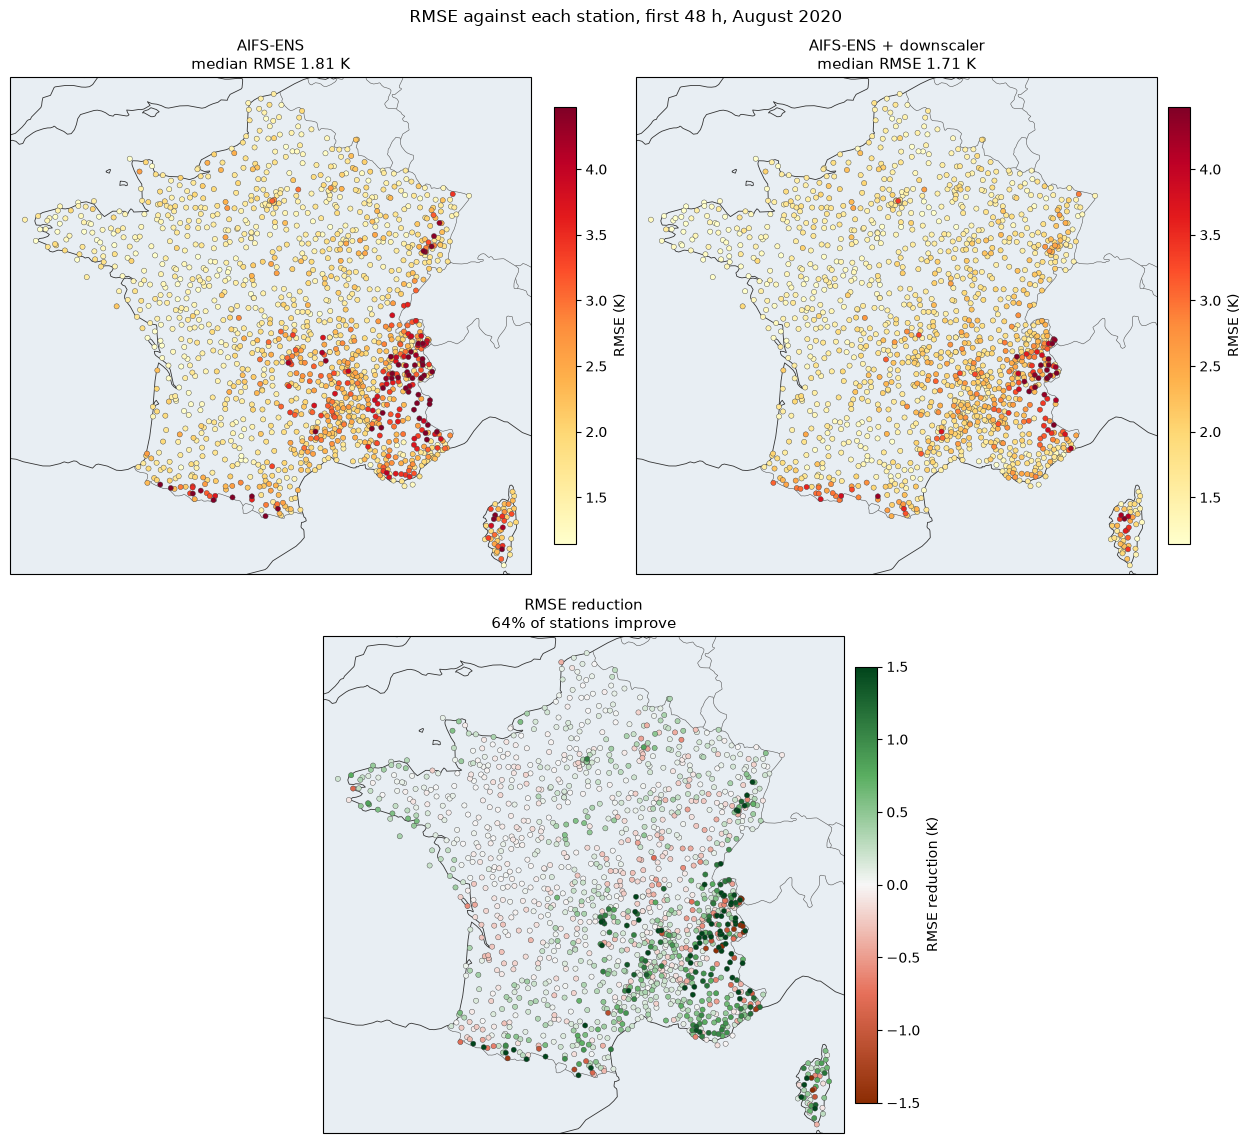

In [14]:
fields = {name: np.concatenate([r["means"][name].reshape(-1, r["means"][name].shape[-1]) for r in results_2020])
          for name in names}
rmse_2020 = {name: station_rmse(fields[name], observed) for name in ("AIFS-ENS", "AIFS-ENS + downscaler")}
fig = station_maps(stations_2020.longitude.values, stations_2020.latitude.values, rmse_2020,
                   title="RMSE against each station, first 48 h, August 2020")

### d.3 Against stations, August 2025

The last check uses the operational forecasts from Earthmover, as you would use the downscaler in
practice, against the August 2025 stations. There is no CERRA for 2025, so there is no floor here; the
one measured in 2020 is the reference. Six runs, four days apart, cover the month; the run of
11 August was already downscaled in section c and is read back.

,AIFS-ENS,AIFS-ENS + downscaler
rmse_K,2.745,2.553
bias_K,0.189,-0.143
crps_K,1.508,1.336
spread_K,1.754,2.070


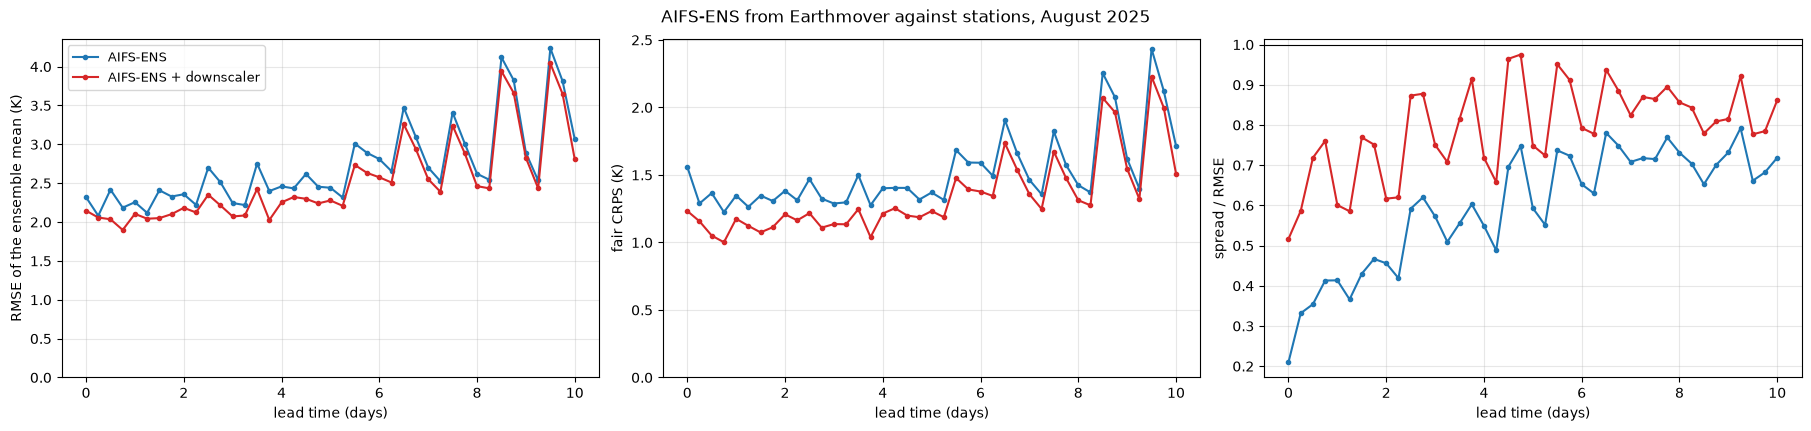

In [15]:
inits_2025 = pd.date_range("2025-08-03", "2025-08-23", freq="4D")   # includes the run from section c
runs_2025 = {init: run(archive, init) for init in inits_2025}
results_2025 = [score(downscaled_2025, stations_2025) for _, downscaled_2025 in runs_2025.values()]

station_scores_2025 = {name: combine_leads([r["stations"][name] for r in results_2025])
                       for name in ("AIFS-ENS", "AIFS-ENS + downscaler")}
fig = lead_figure(station_scores_2025, metrics=("rmse_K", "crps_K", "spread_skill"),
                  title="AIFS-ENS from Earthmover against stations, August 2025")
pd.DataFrame({name: pooled(t) for name, t in station_scores_2025.items()}).round(3)

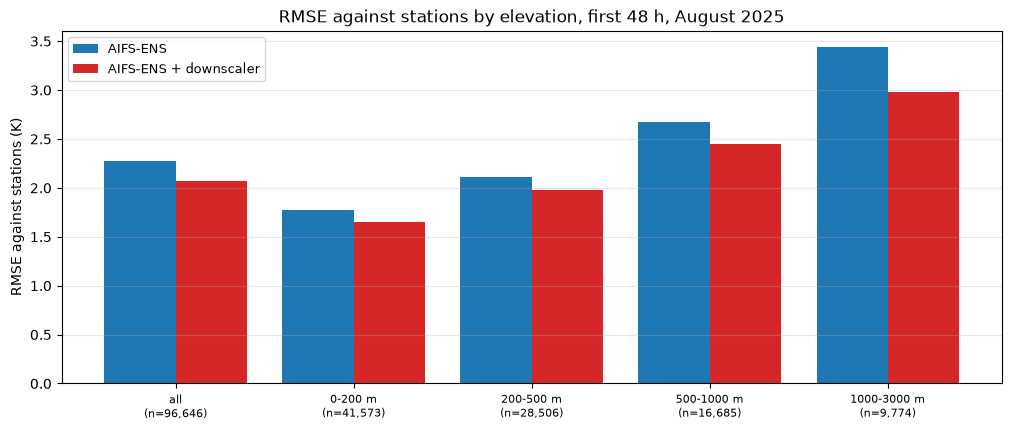

In [16]:
fields = {name: np.concatenate([r["means"][name].reshape(-1, r["means"][name].shape[-1]) for r in results_2025])
          for name in ("AIFS-ENS", "AIFS-ENS + downscaler")}
observed = np.concatenate([r["observed"].reshape(-1, r["observed"].shape[-1]) for r in results_2025])
bands = elevation_scores(fields, observed, stations_2025.elevation.values, [0, 200, 500, 1000, 3000])
fig = elevation_figure(bands, title="RMSE against stations by elevation, first 48 h, August 2025")

And station by station, on the operational forecasts:

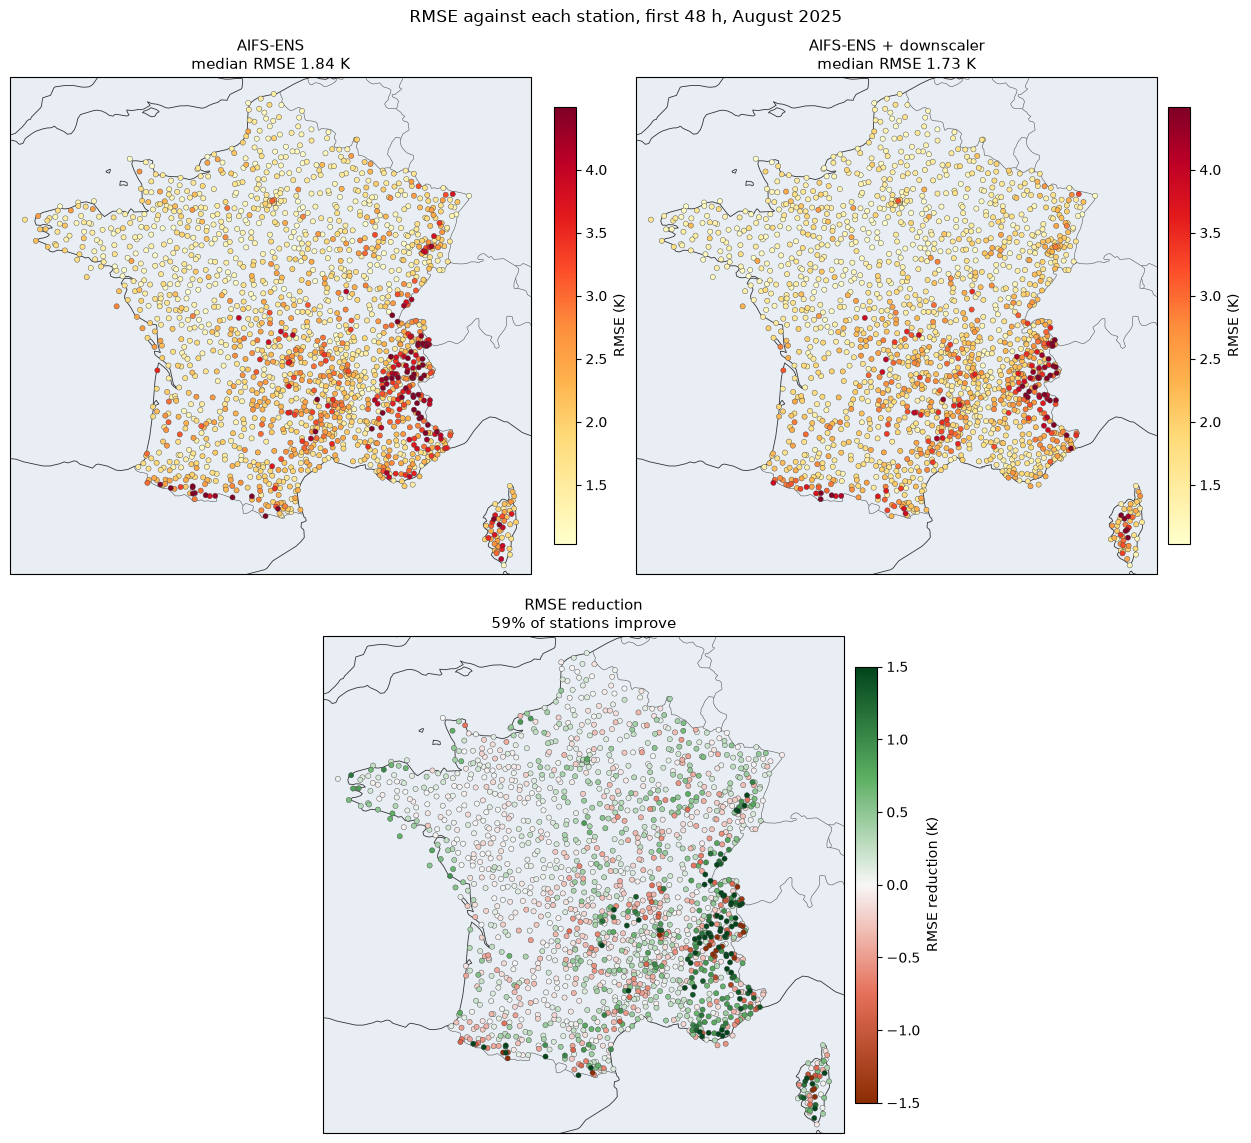

In [17]:
rmse_2025 = {name: station_rmse(fields[name], observed) for name in fields}
fig = station_maps(stations_2025.longitude.values, stations_2025.latitude.values, rmse_2025,
                   title="RMSE against each station, first 48 h, August 2025")